# DiD: aumento de la TISH de Lanús y precios de supermercados

Notebook de replicación del estudio de diferencias en diferencias del proyecto **IPC Alimentos SEPA** (Kevin Pagnotta).

**La política.** La Ordenanza N° 13.772 (30/04/2024) de Lanús fijó una alícuota de 6% de la Tasa por Inspección de
Seguridad e Higiene para hipermercados (código 471110), que antes tributaban 2,3%. El régimen rige desde el 01/08/2024
(Decreto 2.296) y la reglamentación se publicó el 16/09/2024. Los supermercados (471120) y minimercados (471130) no
quedaron alcanzados por el aumento: se los trata como sin cambios.

**Diseño** (en línea con Cawley et al., 2021, y Butters, Sacks y Seo, 2022): se compara el precio del mismo producto, en
el mismo formato de local, entre Lanús y el resto del AMBA, antes y después del aumento.
- **Tratados**: hipermercados de Lanús, alcanzados por el 6% (Coto y Vea). ChangoMás también lo está, pero no
  informó a SEPA en sep–nov 2024 y queda fuera.
- **Control**: los mismos formatos en los otros partidos del AMBA.
- **Placebo**: supermercados de Lanús, no alcanzados por el aumento (DIA y Carrefour Express), contra los mismos formatos en otros partidos.

**Contenido**
1. Datos y definiciones
2. Gráfico de tendencias
3. Estimación DiD
4. Event study
5. Inferencia por permutación
6. Placebo: supermercados (no alcanzados)
7. Tasa de traslado
8. Exportación de tablas
9. Tabla de dispersión de precios (Tabla 1 del documento)

In [1]:
pkgs <- c("fixest", "data.table", "ggplot2")
nuevos <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(nuevos)) install.packages(nuevos, repos = "https://cloud.r-project.org")
suppressPackageStartupMessages({library(fixest); library(data.table); library(ggplot2)})
options(width = 120, warn = 1); invisible(Sys.setlocale("LC_ALL", "C.UTF-8"))
setFixest_nthreads(2)
DATA <- "replication_data"; OUT <- "output"
dir.create(file.path(OUT, "tablas"), recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(OUT, "figuras"), recursive = TRUE, showWarnings = FALSE)
f2 <- function(x, d = 2) formatC(x, format = "f", digits = d, decimal.mark = ",")
MESES_ES <- c("ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic")
etiqueta <- function(m) paste0(MESES_ES[as.integer(substr(m, 6, 7))], "-", substr(m, 3, 4))

## 1. Datos y definiciones

- **Unidad**: producto (EAN) × formato × partido × mes. El precio es el promedio mensual informado a SEPA por las
  sucursales de ese formato en el partido.
- **Outcome**: $y = 100 \cdot \ln(\text{precio})$; los coeficientes se leen como diferencias porcentuales (pp).
- **Panel balanceado por formato**: cada producto tiene precio en todos los meses (abr-24 a oct-25) y en todos los partidos
  donde opera el formato.
- **Timing**: el Decreto 2.296 (01/08/2024) aplica la nueva alícuota desde el anticipo 8° (facturación de agosto de 2024),
  pero los precios recién se ajustan tras la publicación en el Boletín Oficial (16/09/2024). Julio de 2024 es el último mes
  bajo la alícuota anterior (referencia del event study). Agosto y septiembre de 2024 son meses de transición y se excluyen
  del DiD. *Post* = desde octubre de 2024.

In [2]:
FORMATOS <- data.table(id_comercio = c(12L, 9L, 15L, 10L), id_bandera = c(1L, 1L, 1L, 3L),
                       formato = c("Coto", "Vea", "DIA", "Carrefour Express"),
                       grupo = c("Hipermercados", "Hipermercados", "Supermercados", "Supermercados"))
raw <- fread(file.path(DATA, "panel_formato_abr24_oct25.csv.gz"), colClasses = list(character = "ean"))
raw <- merge(raw, FORMATOS, by = c("id_comercio", "id_bandera"))
balancear <- function(x) {
  T <- uniqueN(x$mes)
  part <- x[, .(nt = uniqueN(mes)), by = partido][nt == T, partido]       # partidos con el formato todos los meses
  x <- x[partido %in% part]; np <- length(part)
  ok <- x[, .N, by = ean][N == np * T, ean]                                # productos en todos esos partidos y meses
  x[ean %in% ok]
}
P <- rbindlist(lapply(split(raw, by = "formato"), balancear))
P[, `:=`(y = 100 * log(precio), lanus = as.integer(partido == "Lanus"), post = as.integer(mes >= "2024-10"),
         unidad = paste(formato, ean, partido), prod = paste(formato, ean), mes_f = factor(mes))]
print(P[, .(productos = uniqueN(ean), partidos = uniqueN(partido), lanus = any(lanus == 1), obs = .N), by = .(grupo, formato)])
G <- P[grupo == "Hipermercados"]; N <- P[grupo == "Supermercados"]
TRANSICION <- c("2024-08", "2024-09")

           grupo           formato productos partidos lanus     obs
1: Hipermercados               Vea       601        8  TRUE   91352
2: Supermercados Carrefour Express       549       22  TRUE  229482
3: Hipermercados              Coto      2517       21  TRUE 1004283
4: Supermercados               DIA      1863       24  TRUE  849528


## 2. Gráfico de tendencias

Logaritmo del precio promedio de la canasta de cada formato, Lanús contra el resto del AMBA, normalizado a julio de 2024.
Para el resto del AMBA se promedia sobre los partidos. Formatos con igual peso.

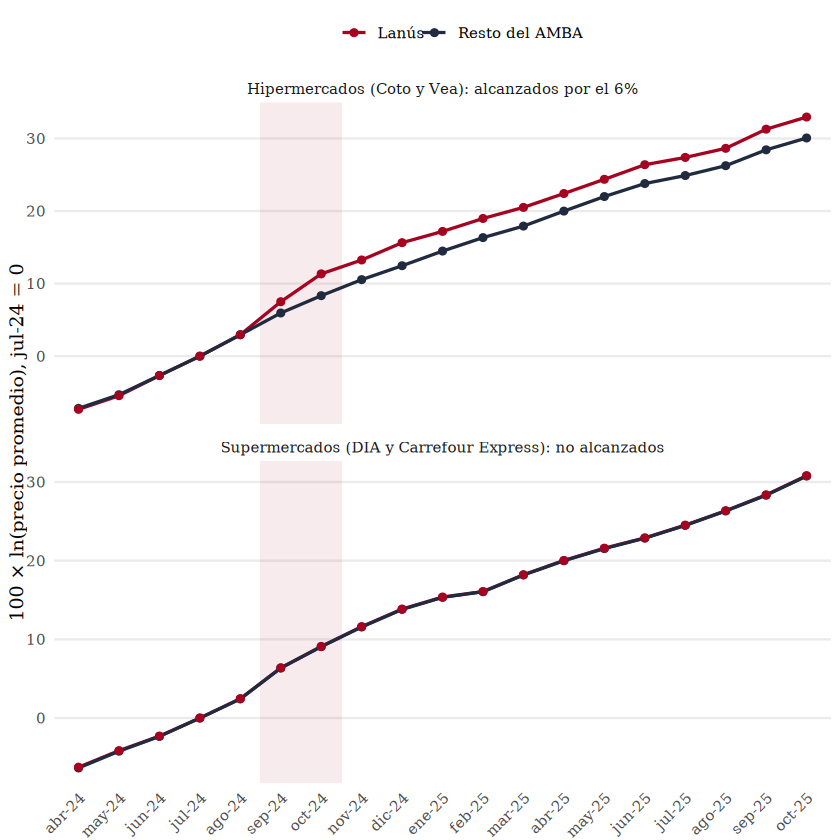

In [3]:
tendencia <- function(d) {
  a <- d[, .(lp = log(mean(precio))), by = .(formato, partido, mes, lanus)]
  a <- a[, .(lp = mean(lp)), by = .(formato, mes, lanus)]
  a[, lp := 100 * (lp - lp[mes == "2024-07"]), by = .(formato, lanus)]
  a[, .(y = mean(lp)), by = .(mes, lanus)]
}
TR <- rbind(tendencia(G)[, panel := "Hipermercados (Coto y Vea): alcanzados por el 6%"],
            tendencia(N)[, panel := "Supermercados (DIA y Carrefour Express): no alcanzados"])
TR[, `:=`(serie = ifelse(lanus == 1, "Lanús", "Resto del AMBA"), lab = factor(etiqueta(mes), levels = etiqueta(sort(unique(mes)))))]
TR[, panel := factor(panel, levels = unique(panel))]
PAL <- c(rojo = "#A60321", azul = "#212B3F", celeste = "#85BAEA")
tema <- theme_minimal(base_family = "serif", base_size = 11) +
  theme(panel.grid.minor = element_blank(), panel.grid.major.x = element_blank(), legend.position = "top",
        axis.text.x = element_text(angle = 45, hjust = 1))
sombra <- annotate("rect", xmin = 5.5, xmax = 7.5, ymin = -Inf, ymax = Inf, fill = PAL[["rojo"]], alpha = 0.08)
g_tend <- ggplot(TR, aes(lab, y, colour = serie, group = serie)) + geom_blank() + sombra +
  geom_line(linewidth = 0.7) + geom_point(size = 1.5) + facet_wrap(~panel, ncol = 1, scales = "free_y") +
  scale_colour_manual(values = c("Lanús" = PAL[["rojo"]], "Resto del AMBA" = PAL[["azul"]]), name = NULL) +
  labs(x = NULL, y = "100 × ln(precio promedio), jul-24 = 0") + tema
ggsave(file.path(OUT, "figuras", "tendencias.pdf"), g_tend, width = 8, height = 7)
g_tend

## 3. Estimación DiD

$$y_{ifpt} = \delta \,(\text{Lanús}_p \times \text{Post}_t) + \alpha_{ifp} + \lambda_{ift} + \varepsilon_{ifpt}$$

con $i$ producto, $f$ formato, $p$ partido y $t$ mes. $\alpha_{ifp}$ es un efecto fijo de unidad (producto en un formato y
partido) y $\lambda_{ift}$ un efecto fijo de producto×formato×mes: se compara el mismo producto, del mismo formato, en el
mismo mes. La columna (1) usa, como Cawley et al. (2021), efectos fijos aditivos (unidad y mes).

Errores estándar agrupados por producto. Con un solo partido tratado, la inferencia de referencia es la de permutación
(sección 5; Conley y Taber, 2011).

In [4]:
Gm <- G[!mes %in% TRANSICION]; Gm[, D := lanus * post]
m1 <- feols(y ~ D | unidad + mes, Gm, cluster = ~prod)
m2 <- feols(y ~ D | unidad + prod^mes, Gm, cluster = ~prod)
m_coto <- feols(y ~ D | unidad + prod^mes, Gm[formato == "Coto"], cluster = ~prod)
m_vea <- feols(y ~ D | unidad + prod^mes, Gm[formato == "Vea"], cluster = ~prod)
etable(m1, m2, m_coto, m_vea, headers = c("FE aditivos", "FE producto×mes", "Coto", "Vea"), digits = 3, fitstat = ~n)
delta <- coef(m2)[["D"]]

,,m1,m2,m_coto,m_vea
,<chr>,<chr>,<chr>,<chr>,<chr>
1,,FE aditivos,FE producto×mes,Coto,Vea
2,Dependent Var.:,y,y,y,y
3,,,,,
4,D,3.52*** (0.086),3.22*** (0.050),3.42*** (0.056),2.30*** (0.104)
5,Fixed-Effects:,---------------,---------------,---------------,---------------
6,unidad,Yes,Yes,Yes,Yes
7,mes,Yes,No,No,No
8,prod-mes,No,Yes,Yes,Yes
9,_______________,_______________,_______________,_______________,_______________


## 4. Event study

$$y_{ifpt} = \sum_{k \neq \text{jul-24}} \delta_k \,(\text{Lanús}_p \times 1[t = k]) + \alpha_{ifp} + \lambda_{ift} + \varepsilon_{ifpt}$$

Los coeficientes previos (abr–jun 2024) y el de agosto (vigencia legal, antes de la publicación) deberían ser cercanos a cero.

In [5]:
event_study <- function(d, ref = "2024-07") {
  e <- feols(as.formula(sprintf("y ~ i(mes_f, lanus, ref = '%s') | unidad + prod^mes", ref)), d, cluster = ~prod)
  E <- data.table(mes = sub("mes_f::(.*):lanus", "\\1", names(coef(e))), coef = coef(e), se = se(e))
  E <- rbind(E, data.table(mes = ref, coef = 0, se = 0))[order(mes)]
  E[, `:=`(lo = coef - 1.96 * se, hi = coef + 1.96 * se, lab = etiqueta(mes))]
  list(modelo = e, tabla = E)
}
ES <- event_study(G)
print(ES$tabla[, .(lab, coef = round(coef, 2), se = round(se, 2))])

       lab  coef   se
 1: abr-24 -0.10 0.03
 2: may-24 -0.09 0.02
 3: jun-24  0.02 0.02
 4: jul-24  0.00 0.00
 5: ago-24  0.04 0.02
 6: sep-24  1.49 0.05
 7: oct-24  3.03 0.05
 8: nov-24  3.17 0.07
 9: dic-24  3.35 0.07
10: ene-25  3.24 0.08
11: feb-25  3.24 0.09
12: mar-25  3.14 0.07
13: abr-25  3.14 0.07
14: may-25  3.20 0.08
15: jun-25  3.26 0.08
16: jul-25  3.14 0.07
17: ago-25  3.00 0.06
18: sep-25  3.13 0.06
19: oct-25  3.19 0.06


## 5. Inferencia por permutación

Se reasigna el tratamiento a cada uno de los otros partidos (sin Lanús en la muestra) y se reestima el modelo. El p-valor
es la proporción de partidos, incluido Lanús, con un efecto al menos tan grande como el de Lanús en valor absoluto
(Abadie, Diamond y Hainmueller, 2010; Conley y Taber, 2011). La franja gris del event study muestra el rango de los
coeficientes de los partidos placebo.

In [6]:
permutar <- function(d, f = y ~ D | unidad + prod^mes) {
  dm <- d[!mes %in% TRANSICION]; dm[, D := lanus * post]; d0 <- coef(feols(f, dm))[["D"]]
  L <- dm[partido != "Lanus"]; Le <- d[partido != "Lanus"]
  r <- rbindlist(lapply(setdiff(unique(d$partido), "Lanus"), function(p) {
    L[, D := as.integer(partido == p) * post]; Le[, tr := as.integer(partido == p)]
    e <- coef(feols(y ~ i(mes_f, tr, ref = "2024-07") | unidad + prod^mes, Le))
    data.table(partido = p, delta = coef(feols(f, L))[["D"]], mes = sub("mes_f::(.*):tr", "\\1", names(e)), coef = e)
  }))
  pd <- unique(r[, .(partido, delta)])
  list(delta = d0, p = mean(abs(c(pd$delta, d0)) >= abs(d0)), placebos = pd,
       banda = rbind(r[, .(pmin = min(coef), pmax = max(coef)), by = mes], data.table(mes = "2024-07", pmin = 0, pmax = 0)))
}
PG <- permutar(G)
cat(sprintf("Hipermercados: delta = %.2f pp | p permutación = %.3f | partidos = %d\n", PG$delta, PG$p, nrow(PG$placebos) + 1))
print(PG$placebos[, .(min = min(delta), max = max(delta))])
PC <- permutar(G[formato == "Coto"]); PV <- permutar(G[formato == "Vea"])
cat(sprintf("Coto: p = %.3f (%d partidos) | Vea: p = %.3f (%d partidos)\n", PC$p, nrow(PC$placebos) + 1, PV$p, nrow(PV$placebos) + 1))

Hipermercados: delta = 3.22 pp | p permutación = 0.048 | partidos = 21


          min       max
1: -0.1789361 0.3579265


Coto: p = 0.048 (21 partidos) | Vea: p = 0.125 (8 partidos)


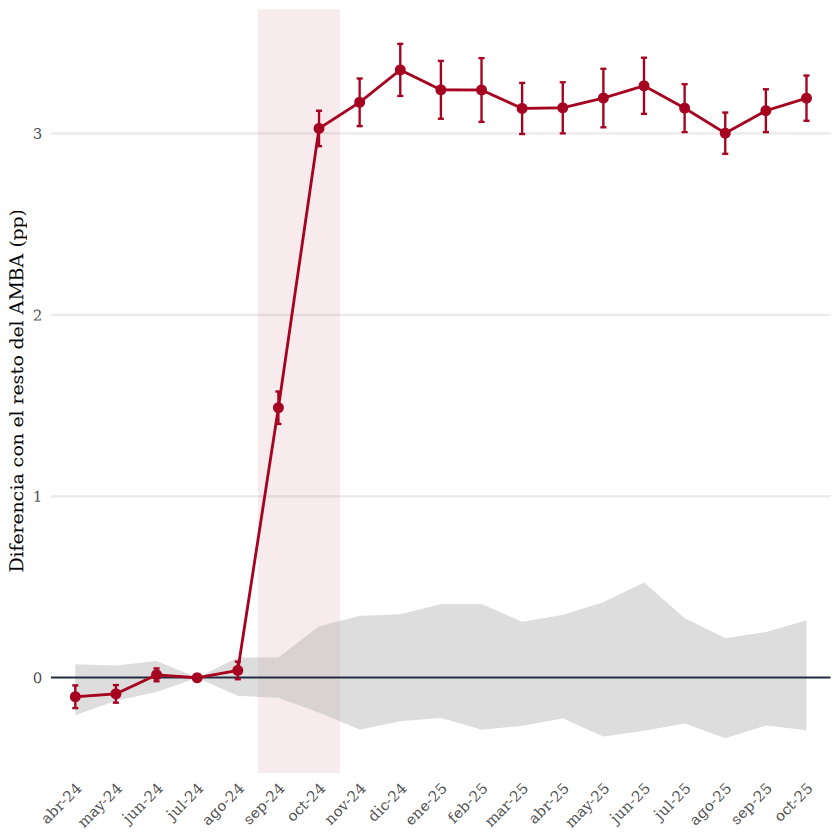

In [7]:
plot_es <- function(E, banda) {
  E <- merge(E, banda, by = "mes")[order(mes)]; E[, lab := factor(lab, levels = lab)]
  ggplot(E, aes(lab, coef, group = 1)) + geom_blank() + sombra +
    geom_ribbon(aes(ymin = pmin, ymax = pmax), fill = "grey70", alpha = 0.45) +
    geom_hline(yintercept = 0, colour = PAL[["azul"]], linewidth = 0.4) +
    geom_errorbar(aes(ymin = lo, ymax = hi), width = 0.15, colour = PAL[["rojo"]]) +
    geom_line(colour = PAL[["rojo"]], linewidth = 0.6) + geom_point(colour = PAL[["rojo"]], size = 2) +
    labs(x = NULL, y = "Diferencia con el resto del AMBA (pp)") + tema
}
g_es <- plot_es(copy(ES$tabla), PG$banda)
ggsave(file.path(OUT, "figuras", "event_study.pdf"), g_es, width = 8, height = 4.8)
perm_plot <- rbind(PG$placebos, data.table(partido = "Lanús", delta = PG$delta))
g_perm <- ggplot(perm_plot, aes(reorder(partido, delta), delta, fill = partido == "Lanús")) + geom_col(width = 0.7) + coord_flip() +
  scale_fill_manual(values = c(`TRUE` = PAL[["rojo"]], `FALSE` = "grey65"), guide = "none") +
  geom_hline(yintercept = 0, colour = PAL[["azul"]], linewidth = 0.4) +
  labs(x = NULL, y = "Efecto estimado (pp)") + tema +
  theme(axis.text.x = element_text(angle = 0))
ggsave(file.path(OUT, "figuras", "permutacion.pdf"), g_perm, width = 7.5, height = 5.5)
g_es

## 6. Placebo: supermercados (no alcanzados)

DIA y Carrefour Express (supermercados y minimercados) no quedaron alcanzados por el 6%. Si el salto de precios en Lanús
fuera un shock propio del partido (por ejemplo, de demanda), también debería verse en estos locales.

Supermercados (DIA y Express): delta = -0.02 pp (ee 0.01) | p permutación = 0.667


             formato       delta         ee         p
1:               DIA -0.01632445 0.01010565 0.6250000
2: Carrefour Express -0.02181107 0.01832534 0.8181818


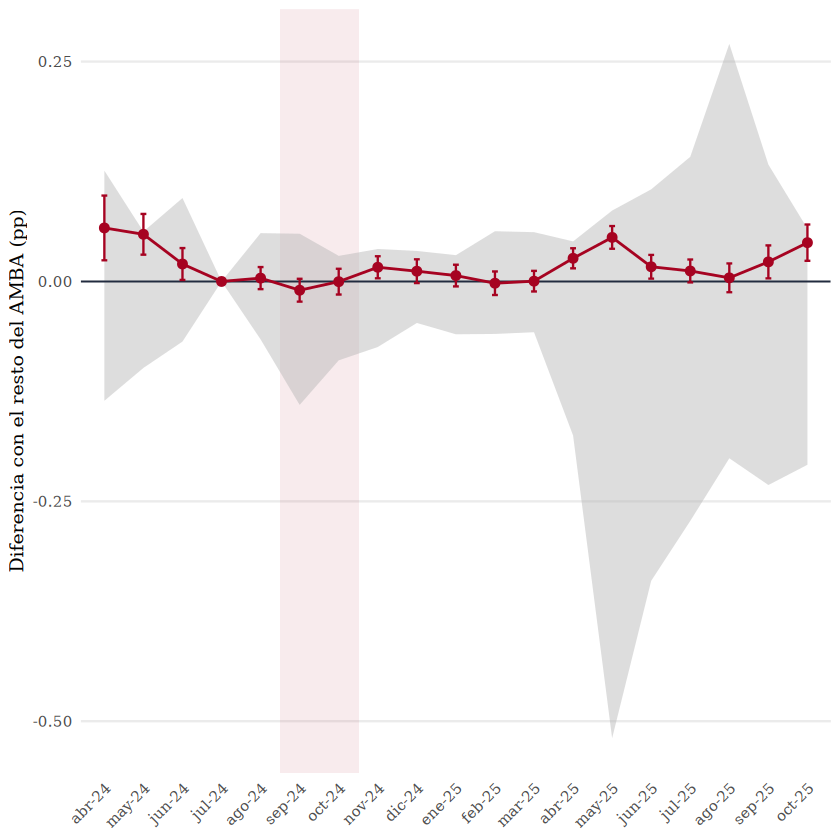

In [8]:
mN <- feols(y ~ D | unidad + prod^mes, N[!mes %in% TRANSICION][, D := lanus * post], cluster = ~prod)
PN <- permutar(N)
ESN <- event_study(N)
cat(sprintf("Supermercados (DIA y Express): delta = %.2f pp (ee %.2f) | p permutación = %.3f\n", coef(mN), se(mN), PN$p))
pl_cad <- rbindlist(lapply(c("DIA", "Carrefour Express"), function(ff) {
  m <- feols(y ~ D | unidad + prod^mes, N[formato == ff & !mes %in% TRANSICION][, D := lanus * post], cluster = ~prod)
  data.table(formato = ff, delta = coef(m)[["D"]], ee = se(m)[["D"]], p = permutar(N[formato == ff])$p) }))
print(pl_cad)
g_esn <- plot_es(copy(ESN$tabla), PN$banda)
ggsave(file.path(OUT, "figuras", "event_study_placebo.pdf"), g_esn, width = 8, height = 4.8)
g_esn

## 7. Tasa de traslado

La TISH grava la facturación neta de IVA. Si el local mantiene su ingreso neto de la tasa, el precio debe subir en
$(1 - 0{,}023)/(1 - 0{,}06)$: $100 \cdot \ln(0{,}977/0{,}94) \approx 3{,}86$ pp (traslado completo). La tasa de traslado es
$\hat\delta / 3{,}86$.

In [9]:
completo <- 100 * log((1 - 0.023) / (1 - 0.06))
TRAS <- data.table(estimacion = c("Hipermercados (Coto y Vea)", "Coto", "Vea"),
                   delta = c(delta, coef(m_coto)[["D"]], coef(m_vea)[["D"]]),
                   ee = c(se(m2)[["D"]], se(m_coto)[["D"]], se(m_vea)[["D"]]), p = c(PG$p, PC$p, PV$p),
                   partidos = c(uniqueN(G$partido), uniqueN(G[formato == "Coto"]$partido), uniqueN(G[formato == "Vea"]$partido)))
TRAS[, traslado := 100 * delta / completo]
cat(sprintf("Traslado completo: %.2f pp\n", completo))
print(TRAS[, lapply(.SD, function(x) if (is.numeric(x)) round(x, 3) else x)])

Traslado completo: 3.86 pp


                   estimacion delta    ee     p partidos traslado
1: Hipermercados (Coto y Vea) 3.216 0.050 0.048       21   83.293
2:                       Coto 3.417 0.056 0.048       21   88.520
3:                        Vea 2.296 0.104 0.125        8   59.466


## 8. Exportación de tablas

In [10]:
fp <- function(x) paste0("(", f2(x), ")")
escribir <- function(l, a) writeLines(l, file.path(OUT, "tablas", a), useBytes = TRUE)
nf <- function(x) formatC(x, big.mark = ".", decimal.mark = ",", format = "d")
mods <- list(m1, m2, m_coto, m_vea)
escribir(c("\\begin{tabular}{lcccc}", "\\toprule", " & (1) & (2) & (3) & (4) \\\\",
  " & Hipermercados & Hipermercados & Coto & Vea \\\\", "\\midrule",
  paste0("Lanús $\\times$ Post & ", paste(sapply(mods, function(m) f2(coef(m)[["D"]])), collapse = " & "), " \\\\"),
  paste0(" & ", paste(sapply(mods, function(m) fp(se(m)[["D"]])), collapse = " & "), " \\\\"),
  paste0("p-valor de permutación & & ", f2(PG$p, 3), " & ", f2(PC$p, 3), " & ", f2(PV$p, 3), " \\\\"), "\\midrule",
  "EF unidad & Sí & Sí & Sí & Sí \\\\", "EF mes & Sí & & & \\\\", "EF producto$\\times$formato$\\times$mes & & Sí & Sí & Sí \\\\",
  paste0("Partidos & ", paste(c(uniqueN(G$partido), uniqueN(G$partido), uniqueN(G[formato == "Coto"]$partido), uniqueN(G[formato == "Vea"]$partido)), collapse = " & "), " \\\\"),
  paste0("Observaciones & ", paste(sapply(mods, function(m) nf(nobs(m))), collapse = " & "), " \\\\"),
  paste0("Traslado (\\%) & & ", paste(f2(TRAS$traslado, 0), collapse = " & "), " \\\\"),
  "\\bottomrule", "\\end{tabular}"), "tabla_did.tex")
E <- ES$tabla; n <- nrow(E); h <- ceiling(n / 2)
escribir(c("\\begin{tabular}{lcc|lcc}", "\\toprule", "Mes & $\\delta_k$ & (e.e.) & Mes & $\\delta_k$ & (e.e.) \\\\", "\\midrule",
  sapply(1:h, function(k) paste(sprintf("%s & %s & %s", E$lab[k], f2(E$coef[k]), ifelse(E$se[k] == 0, "ref.", fp(E$se[k]))), "&",
    if (k + h <= n) sprintf("%s & %s & %s", E$lab[k + h], f2(E$coef[k + h]), fp(E$se[k + h])) else " & & ", "\\\\")),
  "\\bottomrule", "\\end{tabular}"), "tabla_event_study.tex")
escribir(c("\\begin{tabular}{lccc}", "\\toprule", "Supermercados & $\\hat\\delta$ (pp) & (e.e.) & p-valor de permutación \\\\", "\\midrule",
  sprintf("Total (DIA y Carrefour Express) & %s & %s & %s \\\\", f2(coef(mN)[[1]]), fp(se(mN)[[1]]), f2(PN$p, 3)),
  sprintf("%s & %s & %s & %s \\\\", pl_cad$formato, f2(pl_cad$delta), fp(pl_cad$ee), f2(pl_cad$p, 3)),
  "\\bottomrule", "\\end{tabular}"), "tabla_placebo.tex")

## 9. Tabla de dispersión de precios (Tabla 1 del documento)

Total AMBA, dic-23 y oct-26. Panel A: el mismo producto dentro de la misma cadena (cada formato contra sí mismo, entre
partidos y dentro de cada partido). Panel B: el mismo producto entre cadenas del mismo formato (supermercados contra
supermercados e hipermercados contra hipermercados; cada cadena contra el promedio de las demás de su formato), sin Maxi
ni Lanús. Las métricas se calculan en el pipeline del IPC SEPA (Python) y se guardan en `replication_data/`.
Precios idénticos: diferencia de hasta 0,25%.

In [11]:
INDICADORES <- c("Cantidad de precios idénticos (\\%)", "Diferencia de precios mediana (\\%)",
                 "Diferencia de precios promedio (\\%)", "Desvío de precios (\\%)", "SKUs comparados")
panel_disp <- function(archivo) {
  D <- fread(file.path(DATA, archivo))[Cadena == "Total"]; setkey(D, Corte); D <- D[c("dic-23", "oct-26")]
  M <- sapply(c("Identicos_%", "Mediana_%", "Promedio_%", "Desvio_%", "SKUs"), function(v)
    c(D[[paste0("Part_", v)]][1], D[[paste0("Intra_", v)]][1], D[[paste0("Part_", v)]][2], D[[paste0("Intra_", v)]][2]))
  sapply(1:5, function(k) paste(INDICADORES[k], "&", paste(if (k == 5) nf(as.integer(M[, k])) else f2(M[, k]), collapse = " & "), "\\\\"))
}
A <- panel_disp("metricas_dispersion_misma_cadena.csv"); B <- panel_disp("metricas_dispersion_entre_cadenas.csv")
escribir(c("\\begin{tabular}{lcccc}", "\\toprule", " & \\multicolumn{2}{c}{dic-23} & \\multicolumn{2}{c}{oct-26} \\\\",
  "\\cmidrule(lr){2-3}\\cmidrule(lr){4-5}", " & Distintos partidos & Mismo partido & Distintos partidos & Mismo partido \\\\", "\\midrule",
  "\\multicolumn{5}{l}{\\textit{Panel A. Misma cadena}} \\\\", A,
  "\\midrule", "\\multicolumn{5}{l}{\\textit{Panel B. Entre cadenas del mismo formato}} \\\\", B,
  "\\bottomrule", "\\end{tabular}"), "tabla_dispersion.tex")
cat(readLines(file.path(OUT, "tablas", "tabla_dispersion.tex")), sep = "\n")

\begin{tabular}{lcccc}
\toprule
 & \multicolumn{2}{c}{dic-23} & \multicolumn{2}{c}{oct-26} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
 & Distintos partidos & Mismo partido & Distintos partidos & Mismo partido \\
\midrule
\multicolumn{5}{l}{\textit{Panel A. Misma cadena}} \\
Cantidad de precios idénticos (\%) & 68,84 & 76,77 & 83,94 & 89,96 \\
Diferencia de precios mediana (\%) & 0,52 & 0,30 & 0,17 & 0,07 \\
Diferencia de precios promedio (\%) & 1,43 & 1,23 & 0,43 & 0,28 \\
Desvío de precios (\%) & 3,16 & 3,08 & 1,68 & 1,34 \\
SKUs comparados & 14.468 & 14.468 & 40.036 & 40.028 \\
\midrule
\multicolumn{5}{l}{\textit{Panel B. Entre cadenas del mismo formato}} \\
Cantidad de precios idénticos (\%) & 7,39 & 12,83 & 29,14 & 30,50 \\
Diferencia de precios mediana (\%) & 6,64 & 6,11 & 2,12 & 1,75 \\
Diferencia de precios promedio (\%) & 9,78 & 8,91 & 3,09 & 2,56 \\
Desvío de precios (\%) & 13,66 & 12,37 & 4,98 & 4,17 \\
SKUs comparados & 9.937 & 9.808 & 15.821 & 15.627 \\
\bottomrule
\end{tabula

In [12]:
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/blas/libblas.so.3.12.0 
LAPACK: /usr/lib/x86_64-linux-gnu/lapack/liblapack.so.3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8    LC_NUMERIC=C        LC_TIME=C.UTF-8     LC_COLLATE=C.UTF-8  LC_MONETARY=C.UTF-8
 [6] LC_MESSAGES=C       LC_PAPER=C          LC_NAME=C           LC_ADDRESS=C        LC_TELEPHONE=C     
[11] LC_MEASUREMENT=C    LC_IDENTIFICATION=C

time zone: America/Buenos_Aires
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] ggplot2_3.4.4      data.table_1.14.10 fixest_0.14.2     

loaded via a namespace (and not attached):
 [1] sandwich_3.1-0      utf8_1.2.4          generics_0.1.3      dreamerr_1.5.0      lattice_0.22-5     
 [6] digest_0.6.34       magrittr_2.0.3      evaluate_0.23       grid_4.3.3          estima